In [14]:
# K1: make `src` importable (works on Kaggle and locally)
import sys
import subprocess
from pathlib import Path

REPO_USER = "agontuk19"
REPO_NAME = "mars-rover-segmentation"

if Path("/kaggle").exists():
    # ---- Kaggle: clone or pull the latest code from GitHub ----
    ROOT = Path(f"/kaggle/working/{REPO_NAME}")
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
        url = f"https://{token}@github.com/{REPO_USER}/{REPO_NAME}.git"
    except Exception:
        token = None
        url = f"https://github.com/{REPO_USER}/{REPO_NAME}.git"

    cmd = ["git", "-C", str(ROOT), "pull"] if ROOT.exists() else ["git", "clone", url, str(ROOT)]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        msg = result.stderr.replace(token, "***") if token else result.stderr
        raise RuntimeError(f"git failed. Is Internet On? Repo name/token correct?\n{msg}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
else:
    # ---- Local: the repo is already here; notebooks/ sits one level below the root ----
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (ROOT / "src").exists(), f"src/ not found under {ROOT}"
sys.path.append(str(ROOT))

print("Environment:", "Kaggle" if Path("/kaggle").exists() else "local")
print("ROOT:", ROOT)

import torch
print("CUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no CUDA")

Environment: local
ROOT: /Users/tanjimrahman/Workspace/Projects/mars-rover-segmentation
CUDA: False | no CUDA


In [13]:
# K2: data and loaders 
from pathlib import Path

from src.utils.common import seed_everything, get_device
from src.data.preprocessing import IGNORE_INDEX, CLASS_NAMES
from src.data.dataset import load_raw_datasets, load_splits, build_train_val_loaders
import src.data.preprocessing as _prep

ROOT = Path(_prep.__file__).resolve().parents[2]       # folder that contains src/
SPLITS_PATH = ROOT / "data" / "splits.json"
assert SPLITS_PATH.exists(), f"splits.json not found at {SPLITS_PATH}"

SEED, IMG_SIZE, BATCH_SIZE, NUM_WORKERS = 42, 512, 8, 2

seed_everything(SEED)
device = get_device()
raw_datasets = load_raw_datasets()
splits = load_splits(SPLITS_PATH)
train_loader, val_loader = build_train_val_loaders(
    raw_datasets, splits, IMG_SIZE, BATCH_SIZE, NUM_WORKERS, pin_memory=device.type == "cuda")
print(f"Device: {device} | Train: {len(train_loader.dataset)} | Val: {len(val_loader.dataset)}")

Device: mps | Train: 14312 | Val: 1589


             Input Image
                   |
                   v
                  enc1 -------- e1 ------------------+
                   |                                 |
                  Pool                               |
                   |                                 |
                  enc2 -------- e2 --------------+   |
                   |                             |   |
                  Pool                           |   |
                   |                             |   |
                  enc3 -------- e3 ----------+   |   |
                   |                         |   |   |
                  Pool                       |   |   |
                   |                         |   |   |
                  enc4 -------- e4 ------+   |   |   |
                   |                     |   |   |   |
                  Pool                   |   |   |   |
                   |                     |   |   |   |
              Bottleneck                 |   |   |   |
                   |                     |   |   |   |
                  up4                    |   |   |   |
                   |                     |   |   |   |
                Concat <-----------------+   |   |   |
                   |                         |   |   |
                  dec4                       |   |   |
                   |                         |   |   |
                  up3                        |   |   |
                   |                         |   |   |
                Concat <---------------------+   |   |
                   |                             |   |
                  dec3                           |   |
                   |                             |   |
                  up2                            |   |
                   |                             |   |
                Concat <-------------------------+   |
                   |                                 |
                  dec2                               |
                   |                                 |
                  up1                                |
                   |                                 |
                Concat <-----------------------------+
                   |
                  dec1
                   |
                   v
             Segmentation Head
                   |
                   v
             Output (B, 4, H, W)

In [3]:
# K5: baseline training (15 epochs, cosine LR, AMP, resumable)
import torch.nn as nn
from src.training.train import fit
from src.models.unet import UNet

EPOCHS = 15
LR = 1e-3
OUT_DIR = "/kaggle/working/outputs/baseline"

seed_everything(SEED)
model = UNet(in_channels=3, num_classes=4, base=32).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = fit(model, train_loader, val_loader, optimizer, criterion, device,
              epochs=EPOCHS, out_dir=OUT_DIR, scheduler=scheduler, resume=True)

epoch 1 train:   0%|          | 0/1789 [00:00<?, ?it/s]

epoch 1 val:   0%|          | 0/199 [00:00<?, ?it/s]

Epoch  1/15 | train 0.6199 | val 0.3802 | mIoU 0.5586 | IoU [0.765, 0.82, 0.649, 0.0] | 0.38s/batch


epoch 2 train:   0%|          | 0/1789 [00:00<?, ?it/s]

epoch 2 val:   0%|          | 0/199 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c5db03327a0>
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c5db03327a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1655, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    <function _MultiProcessingDataLoaderIter.__

... (53 outputs left out)

epoch 15 train:   0%|          | 0/1789 [00:00<?, ?it/s]

epoch 15 val:   0%|          | 0/199 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c5db03327a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c5db03327a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 15/15 | train 0.1332 | val 0.1369 | mIoU 0.7415 | IoU [0.925, 0.924, 0.86, 0.258] | 0.39s/batch


In [4]:
# Full history table
import json
import pandas as pd

with open("/kaggle/working/outputs/baseline/history.json") as f:
    hist = pd.DataFrame(json.load(f))

cols = ["epoch", "train_loss", "val_loss", "val_miou",
        "val_iou_0", "val_iou_1", "val_iou_2", "val_iou_3"]
print(hist[cols].round(4).to_string(index=False))

 epoch  train_loss  val_loss  val_miou  val_iou_0  val_iou_1  val_iou_2  val_iou_3
     1      0.6199    0.3802    0.5586     0.7653     0.8201     0.6490     0.0000
     2      0.3824    0.4563    0.5558     0.7601     0.8089     0.6543     0.0000
     3      0.3083    0.3643    0.5785     0.8103     0.8267     0.6767     0.0002
     4      0.2673    0.2726    0.6107     0.8642     0.8668     0.7041     0.0078
     5      0.2435    0.2586    0.6251     0.8496     0.8524     0.7982     0.0004
     6      0.2212    0.2279    0.6387     0.8784     0.8853     0.7705     0.0207
     7      0.2027    0.1863    0.6574     0.9007     0.8981     0.8187     0.0122
     8      0.1874    0.1728    0.6837     0.9044     0.9091     0.8153     0.1059
     9      0.1721    0.1763    0.6896     0.9059     0.9103     0.8129     0.1293
    10      0.1640    0.1544    0.6896     0.9111     0.9117     0.8477     0.0879
    11      0.1541    0.1608    0.7045     0.9113     0.9103     0.8300     0.1664
    

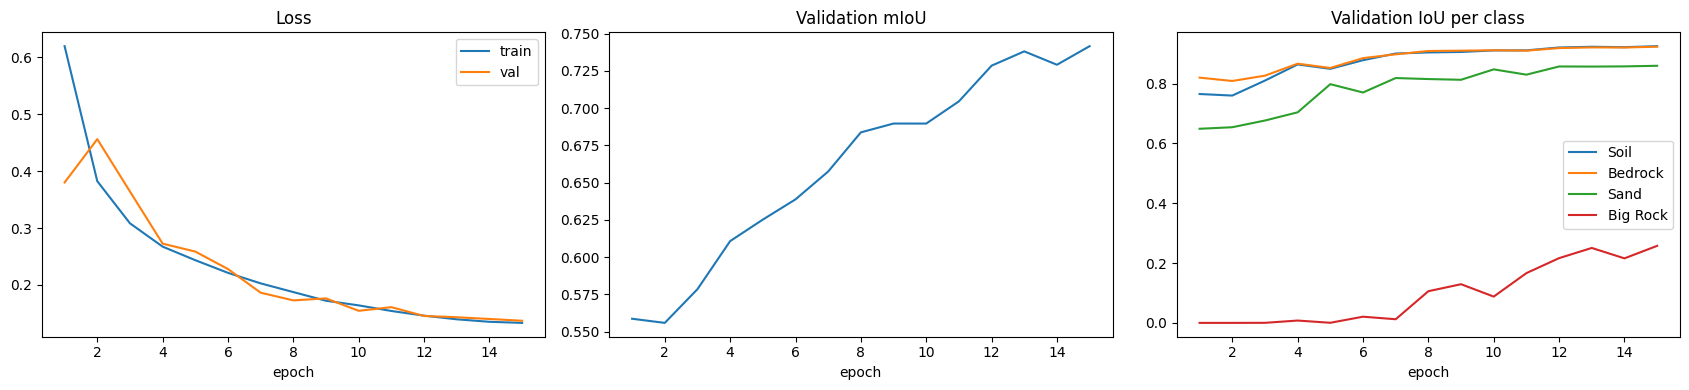

In [5]:
# K6: plot training history
import json
import matplotlib.pyplot as plt

with open("/kaggle/working/outputs/baseline/history.json") as f:
    hist = json.load(f)

epochs = [h["epoch"] for h in hist]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].plot(epochs, [h["train_loss"] for h in hist], label="train")
axes[0].plot(epochs, [h["val_loss"] for h in hist], label="val")
axes[0].set_title("Loss"); axes[0].legend()

axes[1].plot(epochs, [h["val_miou"] for h in hist])
axes[1].set_title("Validation mIoU")

for k, name in CLASS_NAMES.items():
    axes[2].plot(epochs, [h[f"val_iou_{k}"] for h in hist], label=name)
axes[2].set_title("Validation IoU per class"); axes[2].legend()

for ax in axes:
    ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()